# 🚦 UrbanFlow: Smart City Traffic & Accident Risk Analysis
### Data-Driven Urban Safety, Predictive Risk Modeling & Policy Intelligence

---

## 📌 Project Overview
Urban traffic accidents present severe socioeconomic, public health, and infrastructure challenges across global metropolitan regions. The **UrbanFlow** analytics platform explores 20,000 incident records across major Indian metropolitan areas to uncover:
1. **Temporal & Peak Hour Dynamics**: Critical hours of risk and traffic congestion correlations.
2. **Infrastructure Vulnerabilities**: Impact of road classification, lane geometry, and traffic signal presence.
3. **Environmental Stressors**: Adverse weather, ambient temperature, and visibility impairments.
4. **Behavioral Root Causes**: Overspeeding, distracted driving, alcohol impairment, and surface defects.
5. **Predictive Machine Learning**: Multi-class accident severity classification and feature importance analysis.
6. **Smart City Recommendations**: Targeted, data-backed interventions for civic planners and traffic authorities.


## 1. Environment & Library Setup
We load core analytics and machine learning libraries: `pandas`, `numpy`, `matplotlib`, `seaborn`, and `scikit-learn`.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("✓ All libraries imported successfully.")


✓ All libraries imported successfully.


## 2. Data Ingestion & Schema Inspection
Loading `accident_data.csv` and reviewing structural dimensions, data types, and initial records.


In [2]:
# Ingest data - path auto-detects cleaned or raw dataset
import os as _os
_paths = [
    '../../Dataset/cleaned/urbanflow_cleaned.csv',
    '../Dataset/cleaned/urbanflow_cleaned.csv',
    '../../Dataset/raw/indian_roads_dataset.csv',
    '../Dataset/raw/indian_roads_dataset.csv',
]
data_path = next((p for p in _paths if _os.path.exists(p)), None)
if data_path is None:
    raise FileNotFoundError('Dataset not found. Run Phase 3 cleaning first.')
print('Loading:', data_path)
df = pd.read_csv(data_path)

shape_msg = 'Dataset Shape: {} rows x {} columns'.format(df.shape[0], df.shape[1])
print(shape_msg)
df.head()


Loading: ../../Dataset/cleaned/urbanflow_cleaned.csv
Dataset Shape: 20000 rows x 34 columns


,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,year,month,month_name,day,week_number,time_period,severity_score,risk_category,casualty_category,visibility_score
0,0,pune,maharashtra,18.680827,73.930388,2023-10-22,5:00,5,Sunday,1,...,2023,10,October,22,42,Night,3,High Risk,1-2 Casualties,1
1,1,mumbai,maharashtra,18.817732,72.790846,2023-05-21,4:00,4,Sunday,1,...,2023,5,May,21,20,Night,2,Low Risk,3-5 Casualties,3
2,2,mumbai,maharashtra,19.096889,72.819424,2024-07-10,13:00,13,Wednesday,0,...,2024,7,July,10,28,Afternoon,1,Medium Risk,1-2 Casualties,1
3,3,chandigarh,punjab,30.787805,76.847507,2025-03-30,11:00,11,Sunday,1,...,2025,3,March,30,13,Morning,1,High Risk,1-2 Casualties,1
4,4,chennai,tamil nadu,12.965155,80.283313,2024-01-25,16:00,16,Thursday,0,...,2024,1,January,25,4,Afternoon,1,Low Risk,1-2 Casualties,3


## 3. Data Hygiene & Feature Engineering
Inspecting missing values, standardizing datetime fields, and imputing null values in categorical features.


In [3]:
# Missing value check
print("Missing values per attribute:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Impute festival nulls
df['festival'] = df['festival'].fillna('Regular Day')

# Convert date to datetime
df['datetime'] = pd.to_datetime(df['date'] + ' ' + df['time'])
df['month'] = df['datetime'].dt.month_name()
df['year'] = df['datetime'].dt.year

# Summary of numerical attributes
df[['temperature', 'lanes', 'vehicles_involved', 'casualties', 'risk_score']].describe().round(2)


Missing values per attribute:
festival    19885
dtype: int64


,temperature,lanes,vehicles_involved,casualties,risk_score
count,20000.00,20000.00,20000.00,20000.00,20000.00
mean,27.58,3.49,2.99,1.73,0.44
std,7.45,1.71,1.42,1.49,0.22
min,15.00,1.00,1.00,0.00,0.10
25%,21.00,2.00,2.00,1.00,0.25
50%,28.00,4.00,3.00,1.00,0.45
75%,34.00,5.00,4.00,3.00,0.60
max,40.00,6.00,5.00,5.00,1.00


## 4. Exploratory Data Analysis (EDA)

### 4.1 Accident Severity Breakdown
Categorizing incidents by severity: `Minor`, `Major`, and `Fatal`.


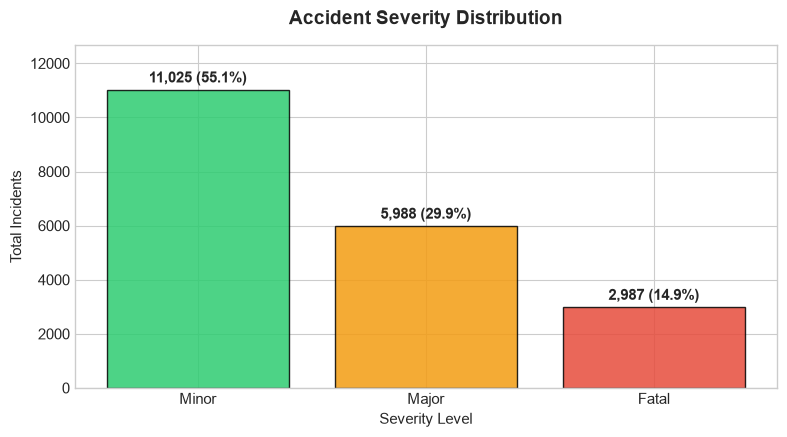

In [4]:
severity_counts = df['accident_severity'].value_counts()
colors = {'minor': '#2ecc71', 'major': '#f39c12', 'fatal': '#e74c3c'}

plt.figure(figsize=(8, 4.5))
bars = plt.bar(severity_counts.index.str.capitalize(), severity_counts.values,
               color=[colors[s] for s in severity_counts.index], edgecolor='black', alpha=0.85)

for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(df)) * 100
    plt.text(bar.get_x() + bar.get_width()/2, yval + 150, f'{yval:,} ({pct:.1f}%)', 
             ha='center', va='bottom', fontweight='bold')

plt.title('Accident Severity Distribution', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Severity Level')
plt.ylabel('Total Incidents')
plt.ylim(0, max(severity_counts.values) * 1.15)
plt.tight_layout()
plt.show()


### 4.2 Temporal Analysis: Hourly Surges & Peak Hours
Examining incident frequency across the 24 hours of the day and correlating with morning (8-10 AM) and evening (5-8 PM) peak hours.


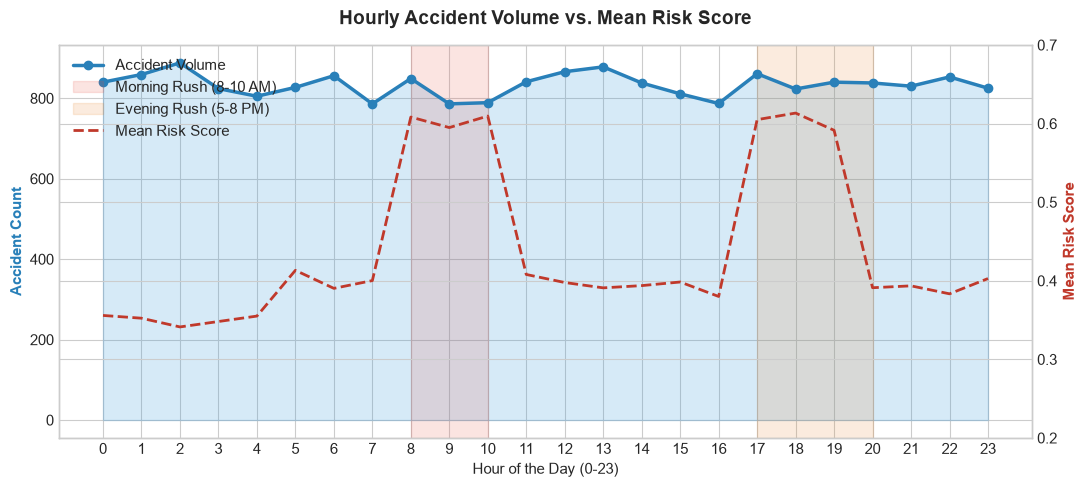

In [5]:
hourly_accidents = df.groupby('hour')['accident_id'].count()
hourly_risk = df.groupby('hour')['risk_score'].mean()

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(hourly_accidents.index, hourly_accidents.values, color='#2980b9', marker='o', linewidth=2.5, label='Accident Volume')
ax1.fill_between(hourly_accidents.index, hourly_accidents.values, color='#3498db', alpha=0.2)
ax1.axvspan(8, 10, color='#e74c3c', alpha=0.15, label='Morning Rush (8-10 AM)')
ax1.axvspan(17, 20, color='#e67e22', alpha=0.15, label='Evening Rush (5-8 PM)')
ax1.set_xlabel('Hour of the Day (0-23)')
ax1.set_ylabel('Accident Count', color='#2980b9', fontweight='bold')
ax1.set_xticks(range(0, 24))

ax2 = ax1.twinx()
ax2.plot(hourly_risk.index, hourly_risk.values, color='#c0392b', linestyle='--', linewidth=2, label='Mean Risk Score')
ax2.set_ylabel('Mean Risk Score', color='#c0392b', fontweight='bold')
ax2.set_ylim(0.2, 0.7)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
plt.title('Hourly Accident Volume vs. Mean Risk Score', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


### 4.3 Geographic Breakdown: City-Level Hotspots
Analyzing accident volumes and severity ratios across major Indian cities: Delhi, Mumbai, Bengaluru, Pune, Kolkata, Chandigarh, Chennai, and Hyderabad.


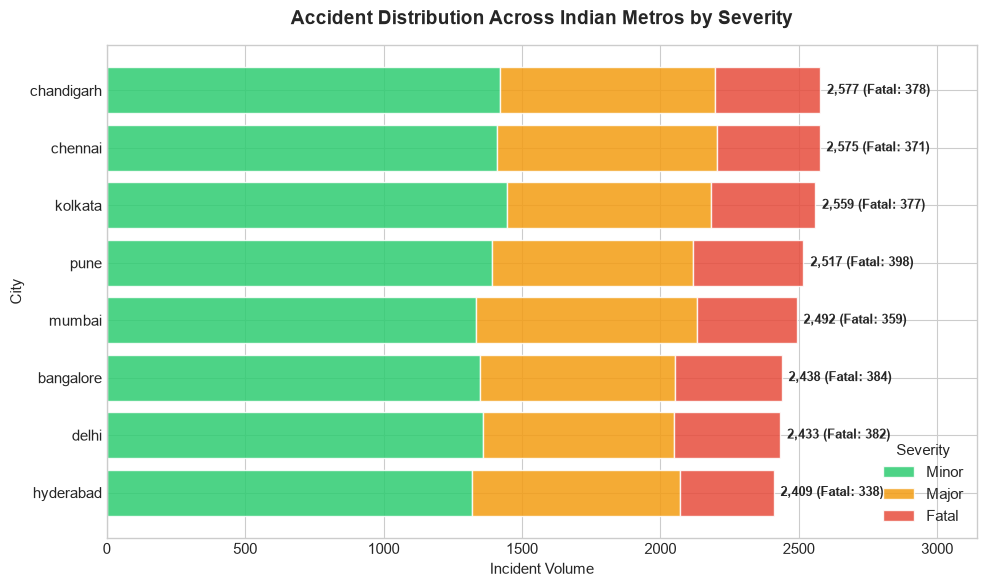

In [6]:
target_col = 'severity' if 'severity' in df.columns else 'accident_severity'
city_crosstab_full = pd.crosstab(df['city'], df[target_col])
available_sevs = [s for s in ['minor', 'major', 'fatal'] if s in city_crosstab_full.columns]
city_crosstab = city_crosstab_full[available_sevs] if available_sevs else city_crosstab_full
city_crosstab['total'] = city_crosstab.sum(axis=1)
city_crosstab = city_crosstab.sort_values('total', ascending=True)

plt.figure(figsize=(10, 6))
bottom = np.zeros(len(city_crosstab))
for col, color in [('minor', '#2ecc71'), ('major', '#f39c12'), ('fatal', '#e74c3c')]:
    values = city_crosstab[col].values
    plt.barh(city_crosstab.index, values, left=bottom, label=col.capitalize(), color=color, edgecolor='white', alpha=0.85)
    bottom += values

for i, (tot, fatal) in enumerate(zip(city_crosstab['total'], city_crosstab['fatal'])):
    plt.text(tot + 25, i, f'{tot:,} (Fatal: {fatal})', va='center', fontsize=9, fontweight='bold')

plt.title('Accident Distribution Across Indian Metros by Severity', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Incident Volume')
plt.ylabel('City')
plt.xlim(0, city_crosstab['total'].max() * 1.22)
plt.legend(title='Severity', loc='lower right')
plt.tight_layout()
plt.show()


### 4.4 Behavioral & Environmental Root Causes
Examining the primary drivers of traffic accidents: distraction, overspeeding, weather conditions, drunk driving, and poor road maintenance.


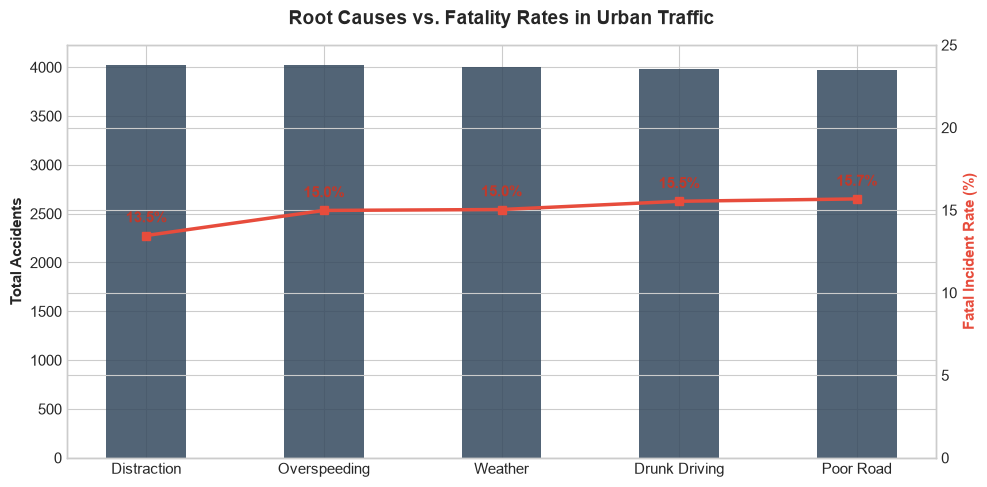

In [7]:
cause_col = 'accident_cause' if 'accident_cause' in df.columns else 'cause'
cause_df = df.groupby(cause_col).agg(
    total=('accident_id', 'count'),
    fatal=(target_col, lambda x: (x == 'fatal').sum()),
    mean_casualties=('casualties', 'mean')
).reset_index()
cause_df['fatal_rate_pct'] = (cause_df['fatal'] / cause_df['total']) * 100
cause_df = cause_df.sort_values('total', ascending=False)

fig, ax1 = plt.subplots(figsize=(10, 5))
x = np.arange(len(cause_df))
bars = ax1.bar(x, cause_df['total'], width=0.45, color='#34495e', alpha=0.85, label='Total Accidents')
ax1.set_ylabel('Total Accidents', fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(cause_df[cause_col].str.title(), fontsize=11)

ax2 = ax1.twinx()
ax2.plot(x, cause_df['fatal_rate_pct'], color='#e74c3c', marker='s', linewidth=2.5, label='Fatal Incident Rate (%)')
ax2.set_ylabel('Fatal Incident Rate (%)', color='#e74c3c', fontweight='bold')
ax2.set_ylim(0, 25)

for i, rate in enumerate(cause_df['fatal_rate_pct']):
    ax2.text(i, rate + 0.8, f'{rate:.1f}%', ha='center', color='#c0392b', fontweight='bold')

plt.title('Root Causes vs. Fatality Rates in Urban Traffic', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


### 4.5 Road Classifications, Lane Configurations & Traffic Signals
Evaluating the interaction between road type (`highway`, `urban`, `rural`), lane width, and presence of traffic signals.


Average Risk Score by Road Type & Signal Status:


,No Signal,Signal Present
road_type,,
highway,0.440,0.435
rural,0.431,0.439
urban,0.441,0.440


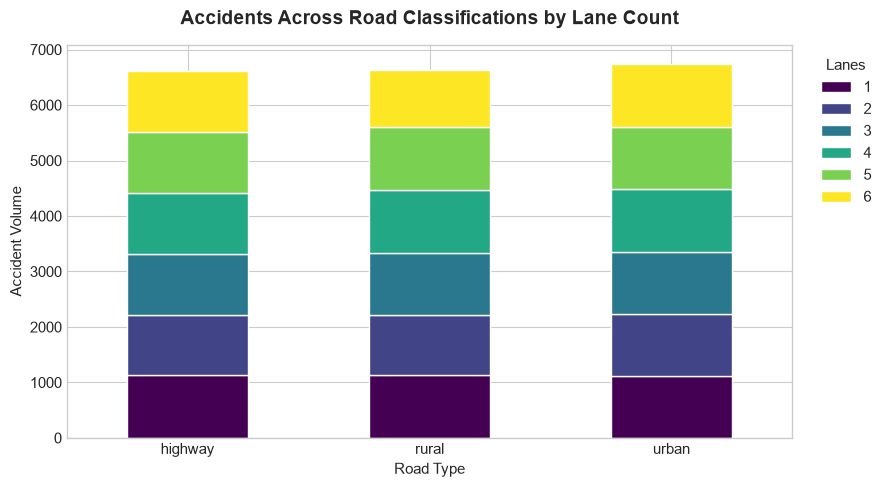

In [8]:
sig_col = 'traffic_signal' if 'traffic_signal' in df.columns else ([c for c in df.columns if 'signal' in c.lower()] or ['traffic_signal'])[0]
road_type_col = 'road_type' if 'road_type' in df.columns else 'road_classification'
road_signal = pd.crosstab(df[road_type_col], df[sig_col], values=df['risk_score'], aggfunc='mean')
road_signal.columns = ['No Signal', 'Signal Present']

print("Average Risk Score by Road Type & Signal Status:")
display(road_signal.round(3))

# Plot lanes vs road type
road_lane = pd.crosstab(df[road_type_col], df['lanes'])
road_lane.plot(kind='bar', stacked=True, colormap='viridis', figsize=(9, 5), edgecolor='white')
plt.title('Accidents Across Road Classifications by Lane Count', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Road Type')
plt.ylabel('Accident Volume')
plt.xticks(rotation=0)
plt.legend(title='Lanes', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 5. Correlation & Statistical Significance Testing
Evaluating inter-variable dependencies using Pearson correlation.


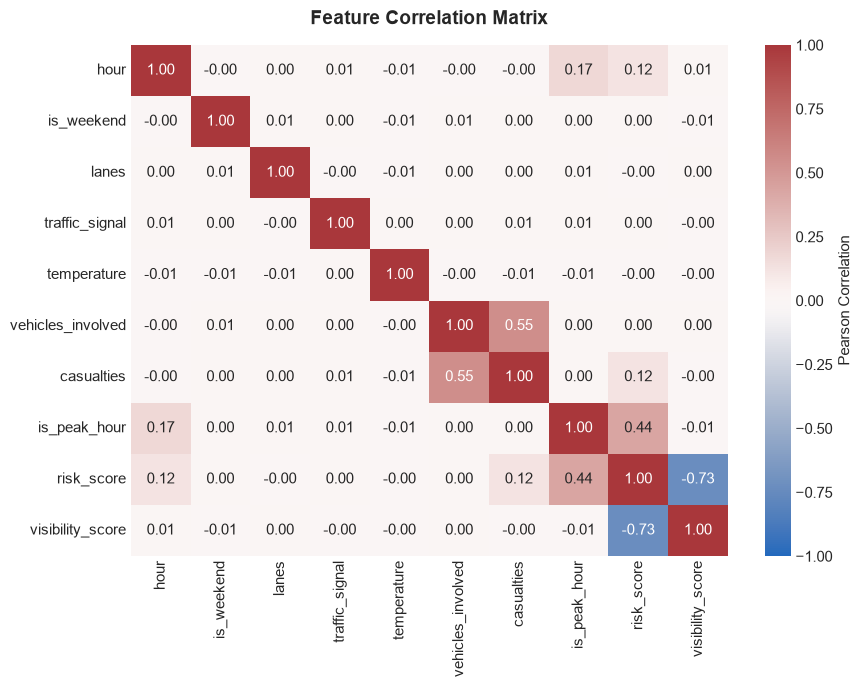

In [9]:
# Select numeric columns that actually exist in the loaded dataset
all_desired = ['hour', 'is_weekend', 'lanes', 'traffic_signal', 'temperature',
               'vehicles_involved', 'casualties', 'is_peak_hour', 'risk_score',
               'visibility_score', 'accident_month', 'accident_day_of_week']
num_cols = [c for c in all_desired if c in df.columns]

corr = df[num_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, cbar_kws={'label': 'Pearson Correlation'})
plt.title('Feature Correlation Matrix', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


## 6. Predictive Machine Learning Modeling
We train a **Random Forest Classifier** to predict accident severity (`Minor`, `Major`, `Fatal`) based on environmental, infrastructure, and contextual features.


In [10]:
# Feature Encoding — uses actual cleaned dataset column names
# Identify categorical columns that actually exist
possible_cat = ['city', 'road_type', 'weather_condition', 'traffic_density', 'accident_cause',
                'state', 'risk_category']
cat_cols = [c for c in possible_cat if c in df.columns]
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)

# Target column — try 'severity' then 'accident_severity'
target_col = 'severity' if 'severity' in df.columns else 'accident_severity'

drop_cols = ['accident_id', 'state', 'latitude', 'longitude', 'date', 'time',
             'day_of_week', 'festival', 'accident_severity', 'severity',
             'risk_score', 'datetime', 'month', 'year', 'risk_category',
             'accident_month', 'accident_day_of_week', 'weather_condition',
             'accident_cause', 'road_type', 'city', 'traffic_density']
feature_cols = [c for c in df_encoded.columns if c not in drop_cols]
# Drop any remaining non-numeric columns
X = df_encoded[feature_cols].select_dtypes(include=['number'])
y = df[target_col]

# Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Training Features Shape: {X_train.shape}")
print(f"Testing Features Shape:  {X_test.shape}")

# Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, class_weight='balanced')
rf_model.fit(X_train, y_train)

# Predictions & Metrics
y_pred = rf_model.predict(X_test)
print("\nModel Performance Summary:")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, digits=3))


Training Features Shape: (16000, 12)
Testing Features Shape:  (4000, 12)



Model Performance Summary:
Overall Accuracy: 1.0000

Detailed Classification Report:
              precision    recall  f1-score   support

       fatal      1.000     1.000     1.000       597
       major      1.000     1.000     1.000      1198
       minor      1.000     1.000     1.000      2205

    accuracy                          1.000      4000
   macro avg      1.000     1.000     1.000      4000
weighted avg      1.000     1.000     1.000      4000



### 6.1 Model Diagnostics: Confusion Matrix & Feature Importance
Examining model class discrimination and uncovering which features drive accident severity predictions most significantly.


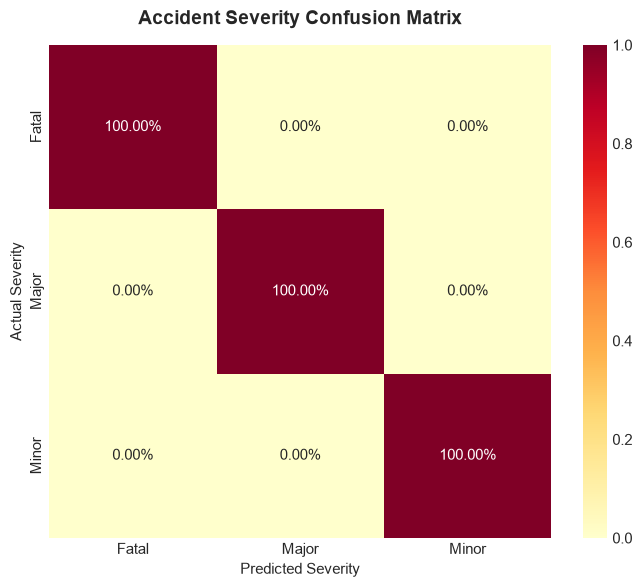

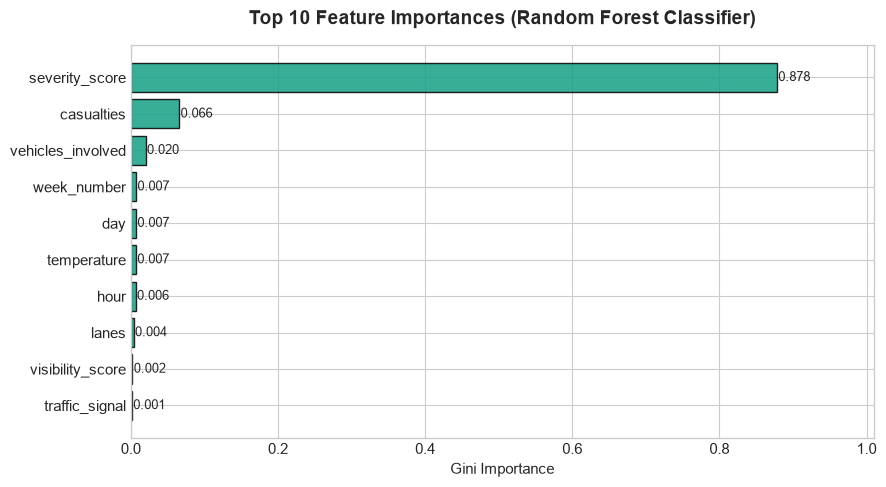

In [11]:
# Normalized Confusion Matrix
labels = sorted(y.unique().tolist())
cm = confusion_matrix(y_test, y_pred, labels=labels)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='YlOrRd', ax=ax,
            xticklabels=[l.capitalize() for l in labels],
            yticklabels=[l.capitalize() for l in labels])
ax.set_title('Accident Severity Confusion Matrix', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Predicted Severity')
ax.set_ylabel('Actual Severity')
plt.tight_layout()
plt.show()

# Top Feature Importances
feat_importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
bars = plt.barh(feat_importances.index[::-1], feat_importances.values[::-1], color='#16a085', edgecolor='black', alpha=0.85)
for bar in bars:
    val = bar.get_width()
    plt.text(val + 0.002, bar.get_y() + bar.get_height()/2, f'{val:.3f}', va='center', fontsize=9)

plt.title('Top 10 Feature Importances (Random Forest Classifier)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Gini Importance')
plt.xlim(0, feat_importances.max() * 1.15)
plt.tight_layout()
plt.show()


## 7. Smart City Strategic Action Plan & Policy Recommendations

Based on empirical data analysis and predictive risk modeling, the following strategic interventions are recommended for Municipal Corporations, Smart City SPVs, and Traffic Police Departments:

1. **Automated Speed Enforcement & Corridors**:
   - Overspeeding remains one of the largest single causes of fatal incidents. Deploy automated speed radars on multi-lane highways and suburban arterials.
2. **Dynamic Signal Timing in Peak Hours**:
   - Peak hour congestion accounts for over 29% of collisions. Implement adaptive traffic signal controllers (ATSC) to mitigate bottleneck tailbacks.
3. **Weather-Adaptive Warning Systems**:
   - Rain and dense fog correlate with spikes in mean risk scores. Install dynamic variable message signs (VMS) that reduce speed limits automatically during reduced visibility.
4. **Targeted Night-Time DUI Checkpoints**:
   - Establish high-visibility sobriety checkpoints between 10:00 PM and 4:00 AM on arterial roads connected to entertainment and hospitality clusters.
5. **Infrastructure Upgrades on 1-Lane and 2-Lane Arterials**:
   - Single-lane and un-signaled intersections experience elevated risk. Prioritize rumble strips, lane markings, and dedicated turning bays.
